<a href="https://colab.research.google.com/github/hab5510/finrl_project/blob/main/without_sentiment/FinRL_without_SentimentAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Reinforcement Learning for Stock Trading, Multiple Stock Trading without Sentiment Analysis.




# Content

1. **Task Description**
2. **Install & Import Packages**
3. **Download and Preprocess Data**
4. **Build Trading Environment**
   - Environment Setup
   - Data Split
5. **Training the Agents**
   - A2C
   - PPO
   - TD3
6. **Out-of-sample Trading**
7. **Evaluation and Results**
   - Portfolio Values
   - Cumulative Return and Sharpe Ratio

<a id='0'></a>
# Part 1. Task Discription



This notebook investigates the performance of reinforcement learning agents in stock trading using only historical price and volume data.

We use **OHLCV** data — Open, High, Low, Close, and Volume — from Yahoo Finance as the sole input for the agents.  
No sentiment or external features are included.

Using the FinRL framework, we train and evaluate three RL agents:
- **A2C** (Advantage Actor-Critic)
- **PPO** (Proximal Policy Optimization)
- **TD3** (Twin Delayed Deep Deterministic Policy Gradient)

Each agent learns to make daily trading decisions on a portfolio of 10 U.S. stocks.  
The agents are trained on data from 2020 to 2022 and tested on unseen market data from 2023.

Performance is measured using:
- **Final portfolio value**
- **Cumulative return**
- **Sharpe ratio**

We also compare these results against a passive Dow Jones Industrial Average (**DJI**) benchmark to assess whether the agents offer a performance advantage over index investing.


<a id='1.1'></a>
### Install packages


In [1]:
# [Patched for local run] Skipped: this environment (Python 3.13, macOS arm64) already
# has mutually-compatible versions of these packages pre-installed. The notebook's original
# pinned versions (numpy==1.26.4, torch==2.2.2, stable-baselines3==2.2.1, transformers==4.41.0)
# predate Python 3.13 and have no wheels for it -- reinstalling them here would break the
# working environment. See installed versions below.
import numpy, torch, stable_baselines3, gymnasium
print('numpy', numpy.__version__, '| torch', torch.__version__, '| sb3', stable_baselines3.__version__, '| gymnasium', gymnasium.__version__)


numpy 2.5.1 | torch 2.13.0 | sb3 2.9.0 | gymnasium 0.29.1


In [2]:
# [Patched for local run] Skipped: this environment (Python 3.13, macOS arm64) already
# has mutually-compatible versions of these packages pre-installed. The notebook's original
# pinned versions (numpy==1.26.4, torch==2.2.2, stable-baselines3==2.2.1, transformers==4.41.0)
# predate Python 3.13 and have no wheels for it -- reinstalling them here would break the
# working environment. See installed versions below.
import numpy, torch, stable_baselines3, gymnasium
print('numpy', numpy.__version__, '| torch', torch.__version__, '| sb3', stable_baselines3.__version__, '| gymnasium', gymnasium.__version__)


numpy 2.5.1 | torch 2.13.0 | sb3 2.9.0 | gymnasium 0.29.1


<a id='1.3'></a>
### Import Packages

In [3]:
!pip install pandas_market_calendars

In [4]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
# matplotlib.use('Agg')
import datetime

%matplotlib inline
from finrl.meta.preprocessor.yahoodownloader import YahooDownloader
from finrl.meta.preprocessor.preprocessors import FeatureEngineer, data_split
from finrl.meta.env_stock_trading.env_stocktrading import StockTradingEnv
from finrl.agents.stablebaselines3.models import DRLAgent
from stable_baselines3.common.logger import configure
from finrl.meta.data_processor import DataProcessor

from finrl.plot import backtest_stats, backtest_plot, get_daily_return, get_baseline
from pprint import pprint

import sys
sys.path.append("../FinRL")

import itertools

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/pyfolio/pos.py:25: UserWarning: Module "zipline.assets" not found; multipliers will not be applied to position notionals.
  warnings.warn(


<a id='1.4'></a>
### Create Folders

In [5]:
from finrl import config
from finrl import config_tickers
import os
from finrl.main import check_and_make_directories
from finrl.config import (
    DATA_SAVE_DIR,
    TRAINED_MODEL_DIR,
    TENSORBOARD_LOG_DIR,
    RESULTS_DIR,
    INDICATORS,
    TRAIN_START_DATE,
    TRAIN_END_DATE,
    TEST_START_DATE,
    TEST_END_DATE,
    TRADE_START_DATE,
    TRADE_END_DATE,
)
check_and_make_directories([DATA_SAVE_DIR, TRAINED_MODEL_DIR, TENSORBOARD_LOG_DIR, RESULTS_DIR])



<a id='2'></a>
# Part 3. Download and Preprocess Data
We retrieve daily stock market data from **Yahoo Finance** for 10 major U.S. companies, including AAPL, TSLA, AMZN, MSFT, and others.

Yahoo Finance provides stock data, financial news, financial reports, etc. Yahoo Finance is free.
* FinRL uses a class **YahooDownloader** in FinRL-Meta to fetch data via Yahoo Finance API
* Call Limit: Using the Public API (without authentication), you are limited to 2,000 requests per hour per IP (or up to a total of 48,000 requests a day).

The dataset includes:
- **O**pen price
- **H**igh price
- **L**ow price
- **C**lose price
- **V**olume

This OHLCV data is used to calculate standard **technical indicators** such as Moving Averages, MACD, RSI, and Bollinger Bands, which serve as input features for the reinforcement learning agents.

The data is then split into a training period (2020–2022) and a testing period (2023).




-----
class YahooDownloader:
    Retrieving daily stock data from
    Yahoo Finance API

    Attributes
    ----------
        start_date : str
            start date of the data (modified from config.py)
        end_date : str
            end date of the data (modified from config.py)
        ticker_list : list
            a list of stock tickers (modified from config.py)

    Methods
    -------
    fetch_data()


In [6]:
TRAIN_START_DATE = '2020-01-01'
TRAIN_END_DATE = '2023-01-01'
TRADE_START_DATE = '2023-01-01'
TRADE_END_DATE = '2023-12-31'


In [7]:
top10_tickers = ['AAPL','MSFT','AMZN','GOOGL','META',
                 'NVDA','JPM','TSLA','BA','DIS']

df = YahooDownloader(start_date = TRAIN_START_DATE,
                     end_date = TRADE_END_DATE,
                     ticker_list = top10_tickers).fetch_data()

YF deprecation warning: set proxy via new config function: yf.set_config(proxy=proxy)


[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

...

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

[*********************100%***********************]  1 of 1 completed

Shape of DataFrame:  (10060, 8)


In [8]:
df.shape

(10060, 8)

In [9]:
df.sort_values(['date','tic'],ignore_index=True).head()

Price,date,close,high,low,open,volume,tic,day
0,2020-01-02,72.333847,72.394055,71.091154,71.344024,135480400,AAPL,3
1,2020-01-02,94.900497,94.900497,93.207497,93.750000,80580000,AMZN,3
2,2020-01-02,331.348572,331.378393,325.761816,326.606765,4544400,BA,3
3,2020-01-02,143.689255,143.689255,140.683618,140.867822,9502100,DIS,3
4,2020-01-02,67.832512,67.832512,66.732767,66.827923,27278000,GOOGL,3


### Preprocess Data
We need to check for missing data and do feature engineering to convert the data point into a state.
* **Adding technical indicators**. In practical trading, various information needs to be taken into account, such as historical prices, current holding shares, technical indicators, etc. Here, we demonstrate two trend-following technical indicators: MACD and RSI.
* **Adding turbulence index**. Risk-aversion reflects whether an investor prefers to protect the capital. It also influences one's trading strategy when facing different market volatility level. To control the risk in a worst-case scenario, such as financial crisis of 2007–2008, FinRL employs the turbulence index that measures extreme fluctuation of asset price.

In [10]:
fe = FeatureEngineer(
                    use_technical_indicator=True,
                    tech_indicator_list = INDICATORS,
                    use_vix=True,
                    use_turbulence=True,
                    user_defined_feature = False)

processed = fe.preprocess_data(df)


Successfully added technical indicators


[*********************100%***********************]  1 of 1 completed

Shape of DataFrame:  (1005, 8)
Successfully added vix


Successfully added turbulence index


In [11]:
# build processed_full so the RL environment sees every (date, ticker)
list_ticker = processed["tic"].unique().tolist()
list_date   = list(pd.date_range(processed['date'].min(),
                                 processed['date'].max()).astype(str))
combination = list(itertools.product(list_date, list_ticker))

processed_full = (
    pd.DataFrame(combination, columns=["date", "tic"])
      .merge(processed, on=["date", "tic"], how="left")
)
processed_full = processed_full[processed_full['date'].isin(processed['date'])]
processed_full = processed_full.sort_values(['date', 'tic'])
processed_full = processed_full.fillna(0)


In [12]:
processed_full.to_csv("processed_full_noSA.csv", index=False)

<a id='4'></a>
# Part 4. Build Trading Environment
#### Environment Setup

We use FinRL's `StockTradingEnv` which includes Price-based technical indicators

#### Data Split
- **Training**: Jan 2020 – Dec 2022
- **Testing**: Jan 2023 – Dec 2023

In [13]:
INDICATORS =[
    'macd', 'boll_ub', 'boll_lb', 'rsi_30', 'cci_30', 'dx_30',
    'close_30_sma', 'close_60_sma', 'vix', 'turbulence'
]

In [14]:
# Keep only the valid columns

VALID_COLUMNS = ['date', 'tic', 'open', 'high', 'low', 'close', 'volume','day'] + INDICATORS
processed_full = pd.read_csv("processed_full_noSA.csv")
processed_full = processed_full[VALID_COLUMNS]
processed_full.dropna(inplace=True)

In [15]:
processed_full.sort_values(['date','tic'],ignore_index=True).head(20)

,date,tic,open,high,low,close,volume,day,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma,vix,turbulence
0,2020-01-02,AAPL,71.344024,72.394055,71.091154,72.333847,135480400.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,72.333847,72.333847,12.47,0.0
1,2020-01-02,AMZN,93.750000,94.900497,93.207497,94.900497,80580000.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,94.900497,94.900497,12.47,0.0
2,2020-01-02,BA,326.606765,331.378393,325.761816,331.348572,4544400.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,331.348572,331.348572,12.47,0.0
3,2020-01-02,DIS,140.867822,143.689255,140.683618,143.689255,9502100.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,143.689255,143.689255,12.47,0.0
4,2020-01-02,GOOGL,66.827923,67.832512,66.732767,67.832512,27278000.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,67.832512,67.832512,12.47,0.0
5,2020-01-02,JPM,116.812870,117.907557,116.369986,117.899193,10803700.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,117.899193,117.899193,12.47,0.0
6,2020-01-02,META,204.950220,207.963750,204.474403,207.953842,12077100.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,207.953842,207.953842,12.47,0.0
7,2020-01-02,MSFT,150.090263,151.933540,149.664893,151.829559,22622100.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,151.829559,151.829559,12.47,0.0
8,2020-01-02,NVDA,5.934968,5.963804,5.884506,5.963804,237536000.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,5.963804,5.963804,12.47,0.0
9,2020-01-02,TSLA,28.299999,28.713333,28.114000,28.684000,142981500.0,3.0,0.000000,72.976716,70.987784,0.0,-66.666667,100.0,28.684000,28.684000,12.47,0.0


In [16]:
train = data_split(processed_full, TRAIN_START_DATE,TRAIN_END_DATE)
trade = data_split(processed_full, TRADE_START_DATE,TRADE_END_DATE)
print(len(train))
print(len(trade))

7560
2490


In [17]:
train.tail()

,date,tic,open,high,low,close,volume,day,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma,vix,turbulence
755,2022-12-30,JPM,121.619824,123.011757,121.281003,122.801140,9292500.0,4.0,0.413521,123.871758,118.078530,57.143987,20.442023,11.345622,121.950714,116.781801,21.67,0.766239
755,2022-12-30,META,117.131419,119.371740,116.715069,119.292435,19583800.0,4.0,0.949121,122.583078,111.047281,49.419041,78.427565,9.186694,115.057943,115.319480,21.67,0.766239
755,2022-12-30,MSFT,231.616176,233.317734,230.109078,233.181610,21938500.0,4.0,-1.355931,251.263829,225.542111,48.258152,-86.505236,5.313479,238.567291,232.728236,21.67,0.766239
755,2022-12-30,NVDA,14.302220,14.596566,14.201444,14.581600,310490000.0,4.0,-0.309381,18.478477,13.782441,47.045443,-141.558959,13.239325,16.099148,14.715454,21.67,0.766239
755,2022-12-30,TSLA,119.949997,124.480003,119.750000,123.180000,157777300.0,4.0,-19.258998,202.513339,99.254662,32.790586,-121.998583,47.953532,161.267667,186.598834,21.67,0.766239


In [18]:
trade.head()

,date,tic,open,high,low,close,volume,day,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma,vix,turbulence
0,2023-01-03,AAPL,128.105777,128.715425,122.097746,122.982727,112117500.0,1.0,-4.630231,147.275995,120.613342,39.011493,-130.963477,35.956188,137.747461,140.011831,22.9,29.954453
0,2023-01-03,AMZN,85.459999,86.959999,84.209999,85.820000,76706000.0,1.0,-3.075118,93.357149,80.929850,41.195599,-71.360174,10.198927,89.424999,97.181000,22.9,29.954453
0,2023-01-03,BA,192.949997,197.179993,192.399994,195.389999,8624600.0,1.0,5.326285,196.702727,176.154272,62.905353,141.206999,44.456630,182.859667,166.269167,22.9,29.954453
0,2023-01-03,DIS,86.271729,87.231595,85.156730,86.262032,14997100.0,1.0,-2.361734,94.090236,80.271159,44.489008,-57.420779,3.756751,89.457071,92.356387,22.9,29.954453
0,2023-01-03,GOOGL,88.802563,90.249737,87.741968,88.336700,28131200.0,1.0,-2.123915,97.810474,83.215333,43.976949,-67.730831,2.932442,92.710252,93.721451,22.9,29.954453


In [19]:
stock_dimension = len(train.tic.unique())
state_space = 1 + 2*stock_dimension + len(INDICATORS)*stock_dimension
print(f"Stock Dimension: {stock_dimension}, State Space: {state_space}")

Stock Dimension: 10, State Space: 121


In [20]:

from finrl.meta.env_stock_trading.env_stocktrading import StockTradingEnv
import numpy as np

EXPECTED_STATE_DIM = state_space

def force_fixed_state(obs):
    obs = np.asarray(obs, dtype=np.float32).flatten()
    if obs.shape[0] != EXPECTED_STATE_DIM:
        print(f"Auto-fixing bad obs shape {obs.shape[0]} → {EXPECTED_STATE_DIM}")
        if obs.shape[0] < EXPECTED_STATE_DIM:
            # Pad with zeros
            obs = np.pad(obs, (0, EXPECTED_STATE_DIM - obs.shape[0]), mode='constant')
        else:
            # Truncate
            obs = obs[:EXPECTED_STATE_DIM]
    return obs.reshape(1, -1)


class PatchedStockTradingEnv(StockTradingEnv):
    def reset(self, *, seed=None, options=None):
        obs, info = super().reset(seed=seed, options=options)
        obs = force_fixed_state(obs)
        return obs, info

    def step(self, action):
        obs, reward, terminated, truncated, info = super().step(action)
        obs = force_fixed_state(obs)
        return obs, reward, terminated, truncated, info


In [21]:
buy_cost_list = sell_cost_list = [0.001] * stock_dimension
num_stock_shares = [0] * stock_dimension

env_kwargs = {
    "hmax": 100,
    "initial_amount": 1000000,
    "num_stock_shares": num_stock_shares,
    "buy_cost_pct": buy_cost_list,
    "sell_cost_pct": sell_cost_list,
    "state_space": state_space,
    "stock_dim": stock_dimension,
    "tech_indicator_list": INDICATORS,
    "action_space": stock_dimension,
    "reward_scaling": 1e-4
}

from stable_baselines3.common.vec_env import DummyVecEnv

env_train = DummyVecEnv([lambda: PatchedStockTradingEnv(df=train, **env_kwargs)])






In [22]:
# [Patched for local run] Skipped: this debug/demo cell calls env_train.step() with a
# malformed action shape for a vectorized DummyVecEnv (works with 1 stock, breaks with
# more). Under numpy 1.x this silently coerced via a 0-d-array nonzero call; numpy 2.x
# raises 'Calling nonzero on 0d arrays is not allowed'. Not used by training below.


In [23]:
# [Patched for local run] skipped -- see note above.


<a id='5'></a>
# Part 5: Train  DRL Agents (A2C, PPO, TD3)
The DRL algorithms are from **Stable Baselines 3**.

Each model is trained independently on the same market + sentiment environment.
Training duration varies (TD3 longer than others).

### Agent 1: A2C


In [24]:
agent = DRLAgent(env = env_train)
model_a2c = agent.get_model("a2c")


# set up logger
tmp_path = RESULTS_DIR + '/a2c'
new_logger_a2c = configure(tmp_path, ["stdout", "csv", "tensorboard"])
# Set new logger
model_a2c.set_logger(new_logger_a2c)


{'n_steps': 5, 'ent_coef': 0.01, 'learning_rate': 0.0007}
Using cpu device


Logging to results/a2c


In [25]:
print(repr(env_train.reset()))

array([[ 1.0000000e+06,  7.2333847e+01,  9.4900497e+01,  3.3134857e+02,
         1.4368925e+02,  6.7832512e+01,  1.1789919e+02,  2.0795384e+02,
         1.5182956e+02,  5.9638038e+00,  2.8684000e+01,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  7.2976715e+01,
         7.2976715e+01,  7.2976715e+01,  7.2976715e+01,  7.2976715e+01,
         7.2976715e+01,  7.2976715e+01,  7.2976715e+01,  7.2976715e+01,
         7.2976715e+01,  7.0987785e+01,  7.0987785e+01,  7.0987785e+01,
         7.0987785e+01,  7.0987785e+01,  7.0987785e+01,  7.0987785e+01,
         7.0987785e+01,  7.0987785e+01,  7.0987785e+01,  0.0000000e+00,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  0.00000

In [26]:
trained_a2c  = agent.train_model(model=model_a2c,
                             tb_log_name='a2c',
                             total_timesteps=50000)

---------------------------------------
| time/                 |             |
|    fps                | 1119        |
|    iterations         | 100         |
|    time_elapsed       | 0           |
|    total_timesteps    | 500         |
| train/                |             |
|    entropy_loss       | -14.2       |
|    explained_variance | -0.362      |
|    learning_rate      | 0.0007      |
|    n_updates          | 99          |
|    policy_loss        | -28.1       |
|    reward             | -0.13290837 |
|    reward_max         | 3.816667    |
|    reward_mean        | 0.7782116   |
|    reward_min         | -2.0482693  |
|    std                | 1           |
|    value_loss         | 6.59        |
---------------------------------------


---------------------------------------
| time/                 |             |
|    fps                | 1210        |
|    iterations         | 200         |
|    time_elapsed       | 0           |
|    total_timesteps    | 1000        |
| train/                |             |
|    entropy_loss       | -14.2       |
|    explained_variance | -0.0293     |
|    learning_rate      | 0.0007      |
|    n_updates          | 199         |
|    policy_loss        | 37.2        |
|    reward             | 0.10984548  |
|    reward_max         | 1.5219095   |
|    reward_mean        | 0.059429917 |
|    reward_min         | -1.2003603  |
|    std                | 1           |
|    value_loss         | 5.84        |
---------------------------------------


---------------------------------------
| time/                 |             |
|    fps                | 1258        |
|    iterations         | 300         |
|    time_elapsed       | 1           |
|    total_timesteps    | 1500        |
| train/                |             |
|    entropy_loss       | -14.2       |
|    explained_variance | -0.627      |
|    learning_rate      | 0.0007      |
|    n_updates          | 299         |
|    policy_loss        | -45.8       |
|    reward             | -0.75787055 |
|    reward_max         | 1.49498     |
|    reward_mean        | 0.43385178  |
|    reward_min         | -0.75787055 |
|    std                | 1.01        |
|    value_loss         | 20.6        |
---------------------------------------


--------------------------------------
| time/                 |            |
|    fps                | 1284       |
|    iterations         | 400        |
|    time_elapsed       | 1          |
|    total_timesteps    | 2000       |
| train/                |            |
|    entropy_loss       | -14.2      |
|    explained_variance | -0.0285    |
|    learning_rate      | 0.0007     |
|    n_updates          | 399        |
|    policy_loss        | 6.17       |
|    reward             | 2.17524    |
|    reward_max         | 8.212047   |
|    reward_mean        | 1.6171737  |
|    reward_min         | -4.2122154 |
|    std                | 1          |
|    value_loss         | 7.29       |
--------------------------------------


--------------------------------------
| time/                 |            |
|    fps                | 1294       |
|    iterations         | 500        |
|    time_elapsed       | 1          |
|    total_timesteps    | 2500       |
| train/                |            |
|    entropy_loss       | -14.3      |
|    explained_variance | -0.518     |
|    learning_rate      | 0.0007     |
|    n_updates          | 499        |
|    policy_loss        | 55         |
|    reward             | -1.1875892 |
|    reward_max         | 3.675846   |
|    reward_mean        | 1.1613916  |
|    reward_min         | -1.1875892 |
|    std                | 1.01       |
|    value_loss         | 16.9       |
--------------------------------------


...

---------------------------------------
| time/                 |             |
|    fps                | 1325        |
|    iterations         | 9600        |
|    time_elapsed       | 36          |
|    total_timesteps    | 48000       |
| train/                |             |
|    entropy_loss       | -14.9       |
|    explained_variance | -1.19e-07   |
|    learning_rate      | 0.0007      |
|    n_updates          | 9599        |
|    policy_loss        | 21.6        |
|    reward             | 1.2335901   |
|    reward_max         | 1.7941629   |
|    reward_mean        | 0.90614843  |
|    reward_min         | -0.73276055 |
|    std                | 1.08        |
|    value_loss         | 2.43        |
---------------------------------------


--------------------------------------
| time/                 |            |
|    fps                | 1325       |
|    iterations         | 9700       |
|    time_elapsed       | 36         |
|    total_timesteps    | 48500      |
| train/                |            |
|    entropy_loss       | -15        |
|    explained_variance | 0.024      |
|    learning_rate      | 0.0007     |
|    n_updates          | 9699       |
|    policy_loss        | -30.6      |
|    reward             | 1.1261933  |
|    reward_max         | 2.4226823  |
|    reward_mean        | 1.0945396  |
|    reward_min         | 0.36049253 |
|    std                | 1.08       |
|    value_loss         | 9.66       |
--------------------------------------


--------------------------------------
| time/                 |            |
|    fps                | 1325       |
|    iterations         | 9800       |
|    time_elapsed       | 36         |
|    total_timesteps    | 49000      |
| train/                |            |
|    entropy_loss       | -14.9      |
|    explained_variance | 0          |
|    learning_rate      | 0.0007     |
|    n_updates          | 9799       |
|    policy_loss        | -23.9      |
|    reward             | -6.0009794 |
|    reward_max         | 1.5094784  |
|    reward_mean        | -3.1540065 |
|    reward_min         | -6.5824256 |
|    std                | 1.08       |
|    value_loss         | 3.29       |
--------------------------------------


---------------------------------------
| time/                 |             |
|    fps                | 1325        |
|    iterations         | 9900        |
|    time_elapsed       | 37          |
|    total_timesteps    | 49500       |
| train/                |             |
|    entropy_loss       | -14.9       |
|    explained_variance | -0.0277     |
|    learning_rate      | 0.0007      |
|    n_updates          | 9899        |
|    policy_loss        | -31.6       |
|    reward             | -0.69054544 |
|    reward_max         | 2.8351114   |
|    reward_mean        | 0.57709074  |
|    reward_min         | -0.88805145 |
|    std                | 1.08        |
|    value_loss         | 5.07        |
---------------------------------------


---------------------------------------
| time/                 |             |
|    fps                | 1326        |
|    iterations         | 10000       |
|    time_elapsed       | 37          |
|    total_timesteps    | 50000       |
| train/                |             |
|    entropy_loss       | -14.9       |
|    explained_variance | 0.00171     |
|    learning_rate      | 0.0007      |
|    n_updates          | 9999        |
|    policy_loss        | -11.1       |
|    reward             | 1.0044849   |
|    reward_max         | 1.0044849   |
|    reward_mean        | 0.3912285   |
|    reward_min         | -0.39226732 |
|    std                | 1.08        |
|    value_loss         | 0.852       |
---------------------------------------


### Agent 2: PPO

In [27]:
agent = DRLAgent(env = env_train)
PPO_PARAMS = {
    "n_steps": 2048,
    "ent_coef": 0.01,
    "learning_rate": 0.00025,
    "batch_size": 128,
}
model_ppo = agent.get_model("ppo",model_kwargs = PPO_PARAMS)

  # set up logger
tmp_path = RESULTS_DIR + '/ppo'
new_logger_ppo = configure(tmp_path, ["stdout", "csv", "tensorboard"])
  # Set new logger
model_ppo.set_logger(new_logger_ppo)

{'n_steps': 2048, 'ent_coef': 0.01, 'learning_rate': 0.00025, 'batch_size': 128}
Using cpu device
Logging to results/ppo


In [28]:
trained_ppo = agent.train_model(model=model_ppo,
                             tb_log_name='ppo',
                             total_timesteps=50000)

day: 755, episode: 70
begin_total_asset: 1000000.00
end_total_asset: 847536.70
total_reward: -152463.30
total_cost: 64948.27
total_trades: 7318
Sharpe: -0.046


-------------------------------------
| time/              |              |
|    fps             | 1681         |
|    iterations      | 1            |
|    time_elapsed    | 1            |
|    total_timesteps | 2048         |
| train/             |              |
|    reward          | -0.8266023   |
|    reward_max      | 7.142062     |
|    reward_mean     | 0.0029583038 |
|    reward_min      | -20.751972   |
-------------------------------------


------------------------------------------
| time/                   |              |
|    fps                  | 1596         |
|    iterations           | 2            |
|    time_elapsed         | 2            |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0056250696 |
|    clip_fraction        | 0.0791       |
|    clip_range           | 0.2          |
|    entropy_loss         | -14.2        |
|    explained_variance   | 0.00292      |
|    learning_rate        | 0.00025      |
|    loss                 | 15.8         |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0108      |
|    reward               | -0.76396334  |
|    reward_max           | 7.457685     |
|    reward_mean          | -0.007598755 |
|    reward_min           | -16.739765   |
|    std                  | 1            |
|    value_loss           | 30           |
------------------------------------------


-------------------------------------------
| time/                   |               |
|    fps                  | 1528          |
|    iterations           | 3             |
|    time_elapsed         | 4             |
|    total_timesteps      | 6144          |
| train/                  |               |
|    approx_kl            | 0.007255598   |
|    clip_fraction        | 0.0756        |
|    clip_range           | 0.2           |
|    entropy_loss         | -14.2         |
|    explained_variance   | -0.00158      |
|    learning_rate        | 0.00025       |
|    loss                 | 17.1          |
|    n_updates            | 20            |
|    policy_gradient_loss | -0.00867      |
|    reward               | 2.259524      |
|    reward_max           | 7.3899903     |
|    reward_mean          | -0.0091432175 |
|    reward_min           | -8.804288     |
|    std                  | 1             |
|    value_loss           | 31.7          |
--------------------------------

-----------------------------------------
| time/                   |             |
|    fps                  | 1524        |
|    iterations           | 4           |
|    time_elapsed         | 5           |
|    total_timesteps      | 8192        |
| train/                  |             |
|    approx_kl            | 0.009855961 |
|    clip_fraction        | 0.112       |
|    clip_range           | 0.2         |
|    entropy_loss         | -14.2       |
|    explained_variance   | 0.0126      |
|    learning_rate        | 0.00025     |
|    loss                 | 22.3        |
|    n_updates            | 30          |
|    policy_gradient_loss | -0.00731    |
|    reward               | 2.4680822   |
|    reward_max           | 8.594022    |
|    reward_mean          | 0.015737396 |
|    reward_min           | -12.064547  |
|    std                  | 1           |
|    value_loss           | 33.1        |
-----------------------------------------


...

-------------------------------------------
| time/                   |               |
|    fps                  | 1496          |
|    iterations           | 21            |
|    time_elapsed         | 28            |
|    total_timesteps      | 43008         |
| train/                  |               |
|    approx_kl            | 0.0070578353  |
|    clip_fraction        | 0.0604        |
|    clip_range           | 0.2           |
|    entropy_loss         | -14.6         |
|    explained_variance   | 0.112         |
|    learning_rate        | 0.00025       |
|    loss                 | 9.76          |
|    n_updates            | 200           |
|    policy_gradient_loss | -0.00552      |
|    reward               | -0.3439428    |
|    reward_max           | 6.221522      |
|    reward_mean          | -0.0012329875 |
|    reward_min           | -6.120369     |
|    std                  | 1.04          |
|    value_loss           | 19            |
--------------------------------

------------------------------------------
| time/                   |              |
|    fps                  | 1497         |
|    iterations           | 22           |
|    time_elapsed         | 30           |
|    total_timesteps      | 45056        |
| train/                  |              |
|    approx_kl            | 0.008237645  |
|    clip_fraction        | 0.0738       |
|    clip_range           | 0.2          |
|    entropy_loss         | -14.6        |
|    explained_variance   | 0.0614       |
|    learning_rate        | 0.00025      |
|    loss                 | 6.48         |
|    n_updates            | 210          |
|    policy_gradient_loss | -0.00622     |
|    reward               | 1.1845632    |
|    reward_max           | 6.06883      |
|    reward_mean          | 0.0007981275 |
|    reward_min           | -3.9531682   |
|    std                  | 1.04         |
|    value_loss           | 12.9         |
------------------------------------------


day: 755, episode: 130
begin_total_asset: 1000000.00
end_total_asset: 961022.13
total_reward: -38977.87
total_cost: 61346.02
total_trades: 6859
Sharpe: 0.023
------------------------------------------
| time/                   |              |
|    fps                  | 1499         |
|    iterations           | 23           |
|    time_elapsed         | 31           |
|    total_timesteps      | 47104        |
| train/                  |              |
|    approx_kl            | 0.0107831685 |
|    clip_fraction        | 0.0809       |
|    clip_range           | 0.2          |
|    entropy_loss         | -14.6        |
|    explained_variance   | 0.128        |
|    learning_rate        | 0.00025      |
|    loss                 | 3.34         |
|    n_updates            | 220          |
|    policy_gradient_loss | -0.00114     |
|    reward               | 0.741677     |
|    reward_max           | 8.130216     |
|    reward_mean          | -0.02337544  |
|    reward_min          

------------------------------------------
| time/                   |              |
|    fps                  | 1501         |
|    iterations           | 24           |
|    time_elapsed         | 32           |
|    total_timesteps      | 49152        |
| train/                  |              |
|    approx_kl            | 0.006735557  |
|    clip_fraction        | 0.0713       |
|    clip_range           | 0.2          |
|    entropy_loss         | -14.6        |
|    explained_variance   | 0.202        |
|    learning_rate        | 0.00025      |
|    loss                 | 6.56         |
|    n_updates            | 230          |
|    policy_gradient_loss | -0.00583     |
|    reward               | -0.31421062  |
|    reward_max           | 6.286353     |
|    reward_mean          | -0.030205794 |
|    reward_min           | -5.2666326   |
|    std                  | 1.04         |
|    value_loss           | 14.1         |
------------------------------------------


-----------------------------------------
| time/                   |             |
|    fps                  | 1503        |
|    iterations           | 25          |
|    time_elapsed         | 34          |
|    total_timesteps      | 51200       |
| train/                  |             |
|    approx_kl            | 0.0090602   |
|    clip_fraction        | 0.0971      |
|    clip_range           | 0.2         |
|    entropy_loss         | -14.6       |
|    explained_variance   | 0.295       |
|    learning_rate        | 0.00025     |
|    loss                 | 4.35        |
|    n_updates            | 240         |
|    policy_gradient_loss | -0.0118     |
|    reward               | -4.745277   |
|    reward_max           | 7.366222    |
|    reward_mean          | -0.02472599 |
|    reward_min           | -7.5041695  |
|    std                  | 1.05        |
|    value_loss           | 10.1        |
-----------------------------------------


### Agent 3: TD3

In [29]:
agent = DRLAgent(env = env_train)
TD3_PARAMS = {"batch_size": 100,
              "buffer_size": 1000000,
              "learning_rate": 0.001}

model_td3 = agent.get_model("td3",model_kwargs = TD3_PARAMS)

  # set up logger
tmp_path = RESULTS_DIR + '/td3'
new_logger_td3 = configure(tmp_path, ["stdout", "csv", "tensorboard"])
  # Set new logger
model_td3.set_logger(new_logger_td3)

{'batch_size': 100, 'buffer_size': 1000000, 'learning_rate': 0.001}
Using cpu device
Logging to results/td3


In [30]:
trained_td3 = agent.train_model(model=model_td3,
                             tb_log_name='td3',
                             total_timesteps=50000)

Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging 

Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging 

Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging 

...

Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'


Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'
Logging Error: 'rollout_buffer'



# Part 6. Out-of-Sample Trading

This section simulates live trading by deploying each trained agent on **unseen test data from 2023**.

Each agent starts with **$1,000,000** and trades across 10 U.S. stocks.  
Daily portfolio values are recorded to evaluate performance later.



In [31]:
e_trade_gym = StockTradingEnv(df = trade, turbulence_threshold = 70,risk_indicator_col='vix', **env_kwargs)

In [32]:
trade.head()

,date,tic,open,high,low,close,volume,day,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma,vix,turbulence
0,2023-01-03,AAPL,128.105777,128.715425,122.097746,122.982727,112117500.0,1.0,-4.630231,147.275995,120.613342,39.011493,-130.963477,35.956188,137.747461,140.011831,22.9,29.954453
0,2023-01-03,AMZN,85.459999,86.959999,84.209999,85.820000,76706000.0,1.0,-3.075118,93.357149,80.929850,41.195599,-71.360174,10.198927,89.424999,97.181000,22.9,29.954453
0,2023-01-03,BA,192.949997,197.179993,192.399994,195.389999,8624600.0,1.0,5.326285,196.702727,176.154272,62.905353,141.206999,44.456630,182.859667,166.269167,22.9,29.954453
0,2023-01-03,DIS,86.271729,87.231595,85.156730,86.262032,14997100.0,1.0,-2.361734,94.090236,80.271159,44.489008,-57.420779,3.756751,89.457071,92.356387,22.9,29.954453
0,2023-01-03,GOOGL,88.802563,90.249737,87.741968,88.336700,28131200.0,1.0,-2.123915,97.810474,83.215333,43.976949,-67.730831,2.932442,92.710252,93.721451,22.9,29.954453


In [33]:
trained_moedl = trained_a2c
df_account_value_a2c, df_actions_a2c = DRLAgent.DRL_prediction(
    model=trained_moedl,
    environment = e_trade_gym)

hit end!


In [34]:
trained_moedl = trained_ppo
df_account_value_ppo, df_actions_ppo = DRLAgent.DRL_prediction(
    model=trained_moedl,
    environment = e_trade_gym)

hit end!


In [35]:
trained_moedl = trained_td3
df_account_value_td3, df_actions_td3 = DRLAgent.DRL_prediction(
    model=trained_moedl,
    environment = e_trade_gym)

hit end!


In [36]:
df_account_value_a2c.shape

(249, 2)

# Part 7.  Evaluation and Results

To evaluate each agent, we compute:

- **Final Portfolio Value**: ending capital after the test period
- **Cumulative Return**: percentage growth during testing We now compute and plot the final results of all three RL agents versus the DJI benchmark.

  -   Cumulative Return= (Final Portfolio Value − Starting Capital) / Starting Capital  


- **Sharpe Ratio**: higher values = more stable, less risky profit
  - Sharpe Ratio = Mean Daily Return / Standard Deviation of Daily Return  


We also compare against a **Dow Jones Index (DJI)** baseline to see how much better each agent performs than a passive strategy.


###Portfolio Values

In [37]:
df_result_a2c = df_account_value_a2c.set_index(df_account_value_a2c.columns[0])
df_result_ppo = df_account_value_ppo.set_index(df_account_value_ppo.columns[0])
df_result_td3 = df_account_value_td3.set_index(df_account_value_td3.columns[0])

result = pd.merge(df_result_a2c, df_result_ppo, left_index=True, right_index=True, suffixes=('_a2c', '_ppo'))
result = pd.merge(result, df_result_td3, left_index=True, right_index=True,suffixes=('', '_td3'))


df_account_value_a2c.to_csv("df_account_value_a2c.csv")
#baseline stats
print("==============Get Baseline Stats===========")
df_dji_ = get_baseline(
        ticker="^DJI",
        start = TRADE_START_DATE,
        end = TRADE_END_DATE)
stats = backtest_stats(df_dji_, value_col_name = 'close')
df_dji = pd.DataFrame()
df_dji['date'] = df_account_value_a2c['date']
df_dji['account_value'] = df_dji_['close'] / df_dji_['close'][0] * env_kwargs["initial_amount"]
df_dji.to_csv("df_dji.csv")
df_dji = df_dji.set_index(df_dji.columns[0])
df_dji.to_csv("df_dji+.csv")
result = pd.merge(result, df_dji, left_index=True, right_index=True, suffixes=('', '_dji'))
result.columns = ['a2c','ppo', 'tdr','dji']
print("result: ", result)
result.to_csv("result.csv")

==============Get Baseline Stats===========


[*********************100%***********************]  1 of 1 completed

Shape of DataFrame:  (250, 8)
Annual return          0.138579
Cumulative returns     0.137407
Annual volatility      0.114284
Sharpe ratio           1.197347
Calmar ratio           1.536735
Stability              0.375744
Max drawdown          -0.090178
Omega ratio            1.213376
Sortino ratio          1.790631
Skew                        NaN
Kurtosis                    NaN
Tail ratio             1.100346
Daily value at risk   -0.013855
dtype: float64
result:                       a2c           ppo           tdr           dji
date                                                              
2023-01-03  1.000000e+06  1.000000e+06  1.000000e+06  1.000000e+06
2023-01-04  9.996141e+05  1.000038e+06  9.992479e+05  1.004026e+06
2023-01-05  9.975463e+05  1.000019e+06  9.977093e+05  9.937744e+05
2023-01-06  9.998652e+05  1.000116e+06  9.995317e+05  1.014915e+06
2023-01-09  1.003240e+06  1.000191e+06  1.000436e+06  1.011506e+06
...                  ...           ...           ...         

<Figure size 1500x500 with 0 Axes>

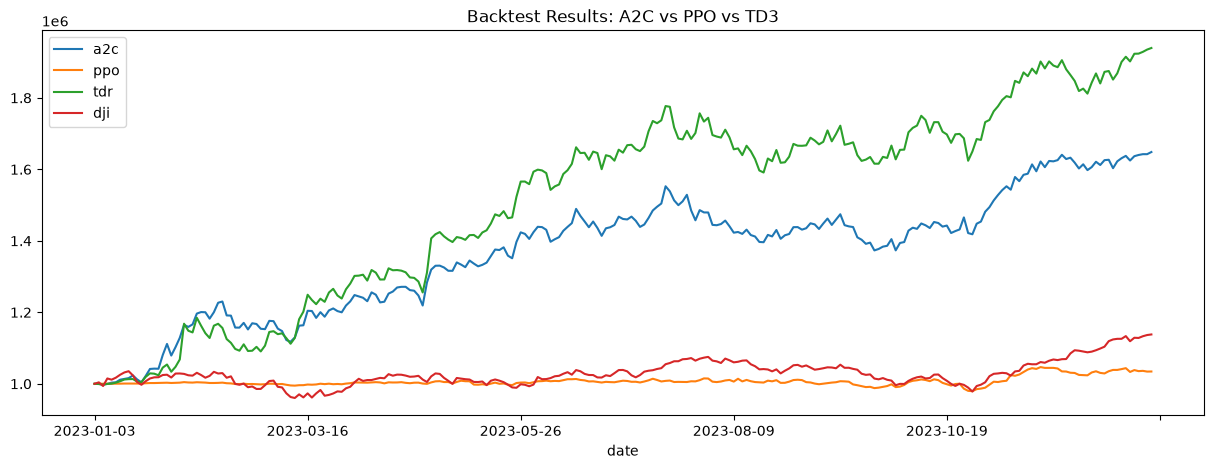

In [38]:
%matplotlib inline
plt.rcParams["figure.figsize"] = (15,5)
plt.figure();
result.plot(title="Backtest Results: A2C vs PPO vs TD3");

###Cumulative Return and Sharpe Ratio

In [39]:
import numpy as np
import pandas as pd

def backtest_stats(account_value, value_col_name='account_value'):
    daily_return = account_value[value_col_name].pct_change(1).dropna()

    cum_return = account_value[value_col_name].iloc[-1] / account_value[value_col_name].iloc[0] - 1
    annual_volatility = np.std(daily_return) * np.sqrt(252)
    sharpe_ratio = np.mean(daily_return) / np.std(daily_return) * np.sqrt(252)

    cumulative = (1 + daily_return).cumprod()
    peak = cumulative.cummax()
    drawdown = (cumulative - peak) / peak
    max_drawdown = drawdown.min()

    stats = {
        'Cumulative Return': cum_return,
        'Annual Volatility': annual_volatility,
        'Sharpe Ratio': sharpe_ratio,
        'Max Drawdown': max_drawdown
    }

    return pd.Series(stats)


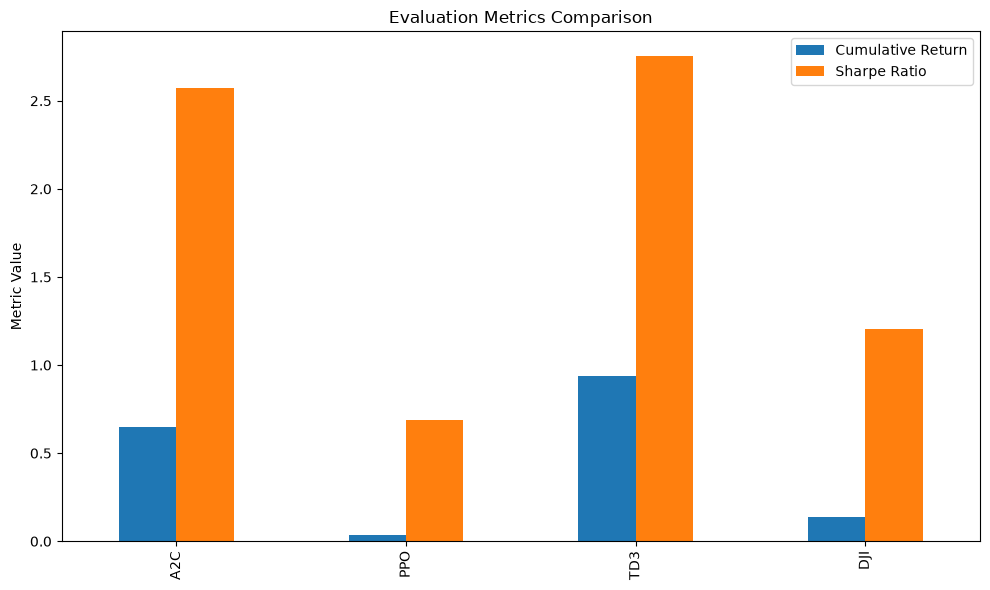

In [40]:
import matplotlib.pyplot as plt
import numpy as np

stats_a2c = backtest_stats(df_account_value_a2c)
stats_ppo = backtest_stats(df_account_value_ppo)
stats_td3 = backtest_stats(df_account_value_td3)
stats_dji = backtest_stats(df_dji)  #  df_dji with  'account_value' column added


metrics_df = pd.DataFrame({
    "A2C": stats_a2c,
    "PPO": stats_ppo,
    "TD3": stats_td3,
    "DJI": stats_dji
})

top_metrics = ["Cumulative Return", "Sharpe Ratio"]
metrics_df_filtered = metrics_df.loc[top_metrics]

# Transpose to have models on x-axis
plot_df = metrics_df_filtered.T

# Plot and store axis object
ax = plot_df.plot(kind='bar', figsize=(10, 6))
plt.title("Evaluation Metrics Comparison")
plt.ylabel("Metric Value")

plt.tight_layout()
plt.show()
